# Un pronóstico causal frente a Huber sobre las mismas observaciones

**Pregunta:** ¿Puede un predictor de operación normal detectar un cambio balanceado de recuperación que
Huber no detecta, y cuántas falsas alarmas acompañan esa ganancia?

Nivel 3 · Requisitos: lecciones 01–02 y partición de entrenamiento, calibración y prueba. · Lectura: 45 minutos.

## Objetivos

Cerrar un balance y predecir un patrón operativo habitual son tareas distintas. Ajustaremos efectivamente
el predictor multicanal de árboles potenciados por histogramas de OreBridge, inspeccionaremos sus retardos
causales y su calibración normal, y lo ejecutaremos junto a Huber con observaciones numéricas idénticas.
Un cambio controlado de recuperación conserva el balance y rompe las relaciones habituales entre canales.
Un ejemplo de sesgo de alimentación y un control sano mostrarán el intercambio entre perturbaciones omitidas
y falsas alarmas. La comparación se limita deliberadamente a tres casos reservados; no busca el mejor detector.

## Preparación

Trabaja en una copia de OreBridge con el entorno de notebooks activo. Los métodos computacionales están en
`data-pipeline/pipeline`; se necesita el repositorio y no se presupone una distribución OreBridge en PyPI.
Instala estas dependencias numéricas exactas una vez, fuera de este notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Inicia el kernel con `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` y `MKL_NUM_THREADS=1`.
La preparación encuentra el repositorio desde el directorio de trabajo sin imprimir una ruta de la máquina.

In [1]:
# Usar el entorno de CPU con versiones fijas e importar los métodos científicos implementados.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.learning import fit_normal, lagged, forecast_scores
from pipeline.model.scenarios import generate, channel_specs, conservation_matrix
from pipeline.stages.plant_evaluate import batch_projection, confusion
specs = channel_specs()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Datos

OreBridge es responsable del generador sintético de autoría propia, con licencia MIT, en
`data-pipeline/pipeline/model/scenarios.py`; [repositorio](https://github.com/fsantibanezleal/CAOS_OreBridge).
El contrato de dieciséis canales está también en `data/derived/PL-01/trace.json`. Regeneraremos las semillas
reales 100–107 de entrenamiento, 200–203 de calibración del pronóstico y 300–307 de calibración separada del
estado. La semilla de prueba 1000 queda fuera de todo ajuste y cálculo de umbrales. El archivo
`data/derived/state-model.json` documenta la configuración canónica; aquí ajustaremos el modelo sin cargar su checkpoint.

## Método

La [implementación mantenida de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) agrega árboles de regresión secuencialmente para reducir
una pérdida predictiva, agrupando las variables mediante histogramas. OreBridge ajusta un regresor por canal
con un envoltorio multisalida. La configuración efectiva usa 70 iteraciones de potenciación, hasta 12 hojas
por árbol, 64 intervalos, regularización L2 de 1 y semilla 41. Estos valores provienen de `learning.fit_normal`;
no indican optimización para una mina operativa. El objetivo es la siguiente observación y el predictor
nunca recibe la máscara de fallas inyectadas.

El vector de entrada es $(y_{t-1},y_{t-2},y_{t-3},y_{t-4})$ para los dieciséis canales. Todo objetivo
es posterior a todas sus variables predictoras. Los registros se escalan mediante las desviaciones estándar
de entrenamiento, reutilizadas al predecir. La calibración mide errores absolutos en secuencias normales
separadas; el umbral de cada canal es su percentil empírico superior 99.5. La puntuación es
$s_{tj}=|y_{tj}-\hat y_{tj}|/q_j$: superar uno es una excedencia calibrada, no una probabilidad posterior
de falla. Primero ejecutamos el ajuste e inspeccionamos cuántos ejemplos utilizó.

In [2]:
# Ajustar el estimador numérico publicado con secuencias normales y sin información de prueba.
bundle = fit_normal()
print(f"Filas normales de entrenamiento: {bundle['normal_training_rows']}; "
      f"filas de calibración del pronóstico: {bundle['calibration_rows']}")
print("Semillas de entrenamiento / calibración del pronóstico:", bundle["train_seeds"],
      "/", bundle["calibration_seeds"])
print(f"Umbral de error absoluto de alimentación a flotación: {bundle['threshold'][5]:.6f} t/h")
parameters = bundle["model"].estimators_[0].get_params()
print("Configuración del estimador ajustado:", {k: parameters[k] for k in ["max_iter", "max_leaf_nodes", "max_bins"]})

Filas normales de entrenamiento: 1568; filas de calibración del pronóstico: 784
Semillas de entrenamiento / calibración del pronóstico: [100, 101, 102, 103, 104, 105, 106, 107] / [200, 201, 202, 203]
Umbral de error absoluto de alimentación a flotación: 23.772435 t/h
Configuración del estimador ajustado: {'max_iter': 70, 'max_leaf_nodes': 12, 'max_bins': 64}


Inspeccionamos una matriz de diseño con el constructor de retardos importado. Doscientas observaciones
y cuatro pasos previos producen 196 objetivos y 64 variables predictoras. El primer objetivo corresponde
al segundo cuatro y sus bloques de entrada a los segundos tres, dos, uno y cero. Ese orden importa al buscar
filtración de información: dividir ventanas solapadas al azar puede filtrar duplicados próximos aunque la
API parezca inocua. Aquí secuencias completas con semillas distintas separan ajuste y calibración.

In [3]:
# Mostrar el orden causal de las ventanas antes de evaluar una perturbación reservada.
normal_sequence = generate(seed=100, steps=200)
features, targets = lagged(normal_sequence.observed)
print(f"Matriz de variables predictoras: {features.shape}; matriz objetivo: {targets.shape}")
print("Primera historia de alimentación, reciente a antigua, t/h:", np.round(features[0, [0, 16, 32, 48]], 4))
print(f"Observación posterior de alimentación: {targets[0, 0]:.4f} t/h")

Matriz de variables predictoras: (196, 64); matriz objetivo: (196, 16)
Primera historia de alimentación, reciente a antigua, t/h: [766.6319 748.7098 755.8005 765.56  ]
Observación posterior de alimentación: 765.9217 t/h


La conciliación de Huber busca un estado compatible con $Ax=0$ y limita la influencia de residuos grandes
([pérdida de Huber](https://doi.org/10.1214/aoms/1177703732)). No recuerda relaciones normales de recuperación más allá de esas ecuaciones.
Para igualar exactamente las entradas, aplicaremos Huber a los mismos vectores del reloj que recibe el
predictor. Calibramos esta convención con semillas normales 300–307: es un experimento identificado como
Huber simultáneo, distinto del balance robusto alineado canónico de la lección 04. Las incertidumbres son
las escalas instrumentales declaradas por el generador. El paquete realiza cada proyección robusta;
la celda solo reúne puntuaciones normales y selecciona sus cuantiles empíricos.

La calibración contempla los residuos habituales de transiciones normales de transporte. No repara una
ecuación errónea ni vuelve identificable una perturbación balanceada. Ambos métodos empiezan en el segundo
catorce para observar exactamente las mismas 146 × 16 entradas de prueba, sin ajustar sus umbrales con ellas.

In [4]:
# Calibrar el residuo simultáneo de Huber sin usar los casos reservados.
matrix = conservation_matrix()
sigma = np.array([s["sigma"] for s in specs])
normal_scores = []
for seed in range(300, 308):
    normal_case = generate(seed=seed)
    scores, _, _ = batch_projection(normal_case.observed[14:], sigma, matrix, robust=True)
    normal_scores.append(scores)
robust_threshold = np.quantile(np.concatenate(normal_scores), 0.995, axis=0, method="higher")
robust_threshold = np.maximum(robust_threshold, 0.1)
print(f"Filas separadas de calibración del estado: {sum(len(x) for x in normal_scores)}")
print(f"Umbral robusto de alimentación a flotación: {robust_threshold[5]:.6f} σ")

Filas separadas de calibración del estado: 1168
Umbral robusto de alimentación a flotación: 6.736266 σ


## Comparación

La familia `engine` del generador modifica el reparto entre concentrado y relaves conservando cada ecuación
afectada. Representa una relación de proceso cambiada o un modelo fijo incompatible, no un sensor cuya falla
esté demostrada. Primero pronosticamos las observaciones reservadas y conservamos predicción, puntuación
residual y etiqueta conocida en variables distintas. Un modelo causal válido puede omitir el comienzo de
un cambio abrupto. Puntuar cada punto afectado, sin extender una alarma a todo el intervalo, permite verlo.

In [5]:
# Ejecutar el predictor causal ajustado con nuevas observaciones y conservar cada error puntual.
changed_relation = generate("engine", seed=1000, severity=2)
forecast_score = forecast_scores(bundle, changed_relation.observed)[14:]
test_features, _ = lagged(changed_relation.observed)
forecast = bundle["model"].predict(test_features / np.tile(bundle["scale"], 4)) * bundle["scale"]
forecast = forecast[10:]
truth = changed_relation.fault[14:]
forecast_metrics = confusion(forecast_score > 1, truth)
print(f"HGB: VP={forecast_metrics['tp']}, FP={forecast_metrics['fp']}, FN={forecast_metrics['fn']}")
print(f"Sensibilidad: {forecast_metrics['recall']:.6f}; "
      f"tasa de falsos positivos: {forecast_metrics['false_positive_rate']:.6f}")

HGB: VP=291, FP=19, FN=9
Sensibilidad: 0.970000; tasa de falsos positivos: 0.009332


Ejecutamos la proyección de Huber sobre esas observaciones exactas, usando los umbrales normales ya fijados.
Para aislar por qué la conservación ayuda poco, regeneramos el caso sano con la misma semilla. Al restarlo
se cancela el mismo ruido aleatorio y queda solo el cambio inyectado. Si su producto con la matriz es cero,
la nueva relación está en el espacio nulo del balance: cerrar exactamente no permite distinguirla de otro estado balanceado.

In [6]:
# Mantener fijas las entradas y medir explícitamente la perturbación nula para la conservación.
robust_score, robust_state, robust_iterations = batch_projection(
    changed_relation.observed[14:], sigma, matrix, robust=True
)
robust_metrics = confusion(robust_score > robust_threshold, truth)
healthy_counterpart = generate("healthy", seed=1000, severity=2)
injected_change = changed_relation.observed - healthy_counterpart.observed
print(f"Huber: VP={robust_metrics['tp']}, FP={robust_metrics['fp']}, FN={robust_metrics['fn']}")
print(f"Sensibilidad: {robust_metrics['recall']:.6f}; "
      f"tasa de falsos positivos: {robust_metrics['false_positive_rate']:.6f}")
print(f"Mayor respuesta de los factores al cambio inyectado: {np.max(np.abs(injected_change @ matrix.T)):.12f}")

Huber: VP=0, FP=4, FN=300
Sensibilidad: 0.000000; tasa de falsos positivos: 0.001965
Mayor respuesta de los factores al cambio inyectado: 0.000000000000


Nos concentramos en sólidos del concentrado para ver la relación cambiada en unidades de ingeniería;
luego comparamos las puntuaciones normalizadas del mismo canal. Dividimos la puntuación de Huber por su
umbral calibrado para que ambos métodos tengan nivel de excedencia uno. Esa convención iguala la regla
de alarma; no iguala las pérdidas, fuentes de información ni distribuciones de las puntuaciones.

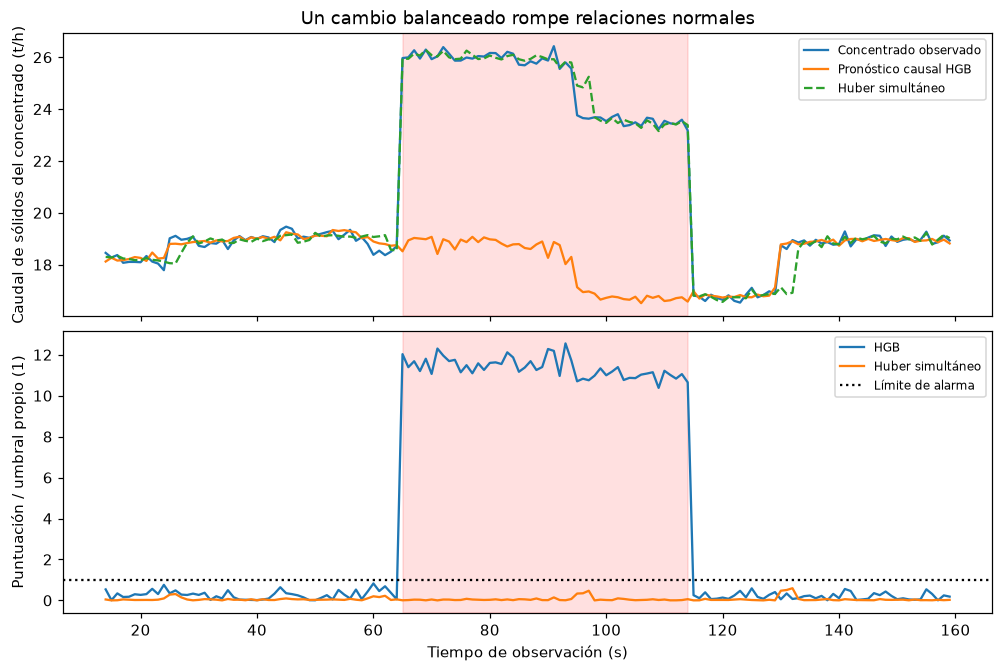

In [7]:
# Mostrar las mismas observaciones de concentrado, dos estimaciones y sus puntuaciones calibradas.
time_s = np.arange(14, 160)
channel = 6
fig, axes = plt.subplots(2, 1, figsize=(9, 6), layout="constrained", sharex=True)
axes[0].plot(time_s, changed_relation.observed[14:, channel], label="Concentrado observado")
axes[0].plot(time_s, forecast[:, channel], label="Pronóstico causal HGB")
axes[0].plot(time_s, robust_state[:, channel], linestyle="--", label="Huber simultáneo")
axes[0].set(title="Un cambio balanceado rompe relaciones normales", ylabel="Caudal de sólidos del concentrado (t/h)")
axes[1].plot(time_s, forecast_score[:, channel], label="HGB")
axes[1].plot(time_s, robust_score[:, channel] / robust_threshold[channel], label="Huber simultáneo")
axes[1].axhline(1, color="black", linestyle=":", label="Límite de alarma")
axes[1].set(xlabel="Tiempo de observación (s)", ylabel="Puntuación / umbral propio (1)")
for axis in axes:
    axis.axvspan(65, 114, alpha=0.12, color="red")
    axis.legend(fontsize=8)
plt.show()

La lectura de concentrado se aparta de la relación que el predictor aprendió con otros canales, mientras
un estado Huber compatible con conservación puede seguir cerca de la nueva observación. El panel inferior
explica el desacuerdo: el predictor pregunta si la historia multicanal previa permitía esperar ese valor;
la conciliación pregunta cuánto debe moverlo para cerrar los factores admitidos. El intervalo rojo muestra
verdad solo para interpretar y no entra en ninguna inferencia. Una puntuación predictiva mayor no identifica
por sí sola si cambió el proceso, el instrumento o la relación fija.

Agregamos un sesgo directo de alimentación y un control sano sin cambiar modelos ni umbrales. Conservar solo
el ejemplo de recuperación ocultaría la carga de alertas. La precisión es indefinida sin alarmas y la
sensibilidad es indefinida sin fallas. El cálculo de confusión importado devuelve un valor nulo en esos
casos; lo conservamos, sin presentar la sensibilidad del control sano como perfecta ni como cero.

In [8]:
# Conservar los controles reservados y todas las falsas alarmas de la comparación.
comparisons = {"engine": {"HGB": forecast_metrics, "Huber": robust_metrics}}
for family in ["bias", "healthy"]:
    case = generate(family, seed=1000, severity=2)
    predicted = forecast_scores(bundle, case.observed)[14:]
    projected, _, _ = batch_projection(case.observed[14:], sigma, matrix, robust=True)
    comparisons[family] = {
        "HGB": confusion(predicted > 1, case.fault[14:]),
        "Huber": confusion(projected > robust_threshold, case.fault[14:]),
    }
family_names = {"engine": "Cambio de recuperación", "bias": "Sesgo de alimentación", "healthy": "Control sano"}
for family, methods in comparisons.items():
    for method, metrics in methods.items():
        recall_text = "nulo (indefinido)" if metrics["recall"] is None else f"{metrics['recall']:.6f}"
        print(f"{family_names[family]} / {method}: sensibilidad={recall_text}; falsas alarmas={metrics['fp']}")

Cambio de recuperación / HGB: sensibilidad=0.970000; falsas alarmas=19
Cambio de recuperación / Huber: sensibilidad=0.000000; falsas alarmas=4
Sesgo de alimentación / HGB: sensibilidad=1.000000; falsas alarmas=62
Sesgo de alimentación / Huber: sensibilidad=0.700000; falsas alarmas=4
Control sano / HGB: sensibilidad=nulo (indefinido); falsas alarmas=9
Control sano / Huber: sensibilidad=nulo (indefinido); falsas alarmas=4


Comparamos sensibilidad solo donde existe un denominador de perturbación y mostramos tasas de falsos
positivos para los tres casos. Ambos paneles usan porcentajes, pero sus denominadores difieren: entradas
canal-tiempo afectadas para sensibilidad y entradas sanas para falsos positivos. Contar eventos en vez de
puntos respondería otra pregunta. Son pocos casos para explicar mecanismos, no para estimar un intervalo
de confianza de una flota industrial ni afirmar superioridad general.

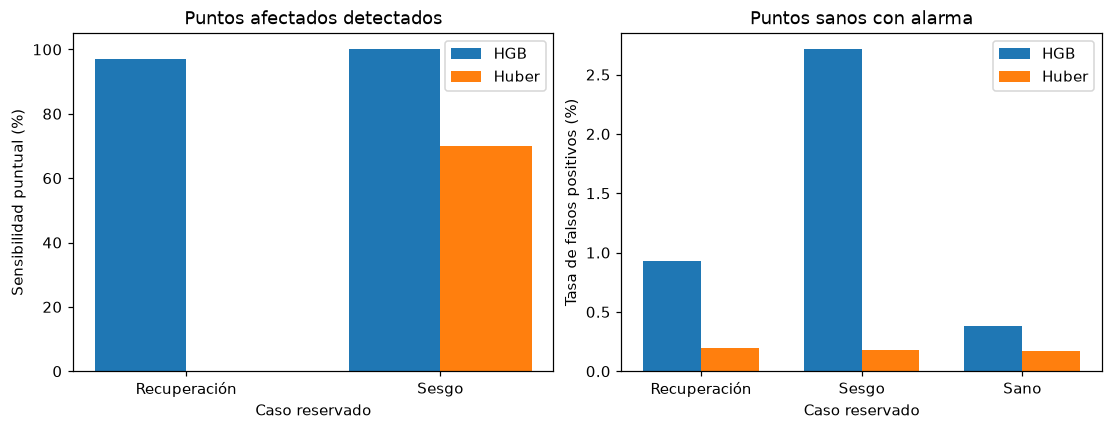

In [9]:
# Mostrar las ganancias de detección y los costos de alertas con sus denominadores distintos.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for offset, method in [(-0.18, "HGB"), (0.18, "Huber")]:
    recalls = [100 * comparisons[f][method]["recall"] for f in ["engine", "bias"]]
    false_rates = [100 * comparisons[f][method]["false_positive_rate"] for f in comparisons]
    axes[0].bar(np.arange(2) + offset, recalls, 0.36, label=method)
    axes[1].bar(np.arange(3) + offset, false_rates, 0.36, label=method)
axes[0].set_xticks([0, 1], ["Recuperación", "Sesgo"])
axes[1].set_xticks([0, 1, 2], ["Recuperación", "Sesgo", "Sano"])
axes[0].set(title="Puntos afectados detectados", ylabel="Sensibilidad puntual (%)", xlabel="Caso reservado")
axes[1].set(title="Puntos sanos con alarma", ylabel="Tasa de falsos positivos (%)", xlabel="Caso reservado")
for axis in axes:
    axis.legend()
plt.show()

El predictor detecta más puntos de ambas perturbaciones en esta comparación, pero también alerta más sobre
entradas sanas. El control sano es esencial: no tiene sensibilidad definida, aunque sí permite medir alertas
molestas. Los umbrales simultáneos de Huber absorben parte de la variación normal de transporte y pueden
reducir tanto falsas alarmas como sensibilidad. Esto motiva un modelo temporal físicamente justificado,
no ajustes de umbral con datos de prueba. El siguiente notebook vuelve a la evaluación alineada canónica
y mide las ablaciones completas de tiempo, motor y topología.

La predicción de anomalías con grafos ya aprende relaciones entre sensores: [GDN](https://arxiv.org/abs/2106.06947)
es un antecedente pertinente. Aquí no implementamos ni ejecutamos GDN, y no renombramos el predictor por
histogramas como red de grafos. Los componentes publicados ejecutados son los árboles potenciados de
scikit-learn y la pérdida de Huber implementada por la proyección robusta de OreBridge. Así una referencia
bibliográfica no se convierte en una comparación experimental que no se hizo.

## Resultados

**Respuesta:** El ajuste usa 1568 filas normales de entrenamiento y 784 de calibración predictiva. Ante el
cambio balanceado detecta 291 de 300 puntos afectados, con sensibilidad de 97.000000%, mientras Huber
simultáneo detecta 0 de 300. El predictor genera 19 falsas alarmas frente a 4 de Huber en ese caso. Para el
sesgo de alimentación sus sensibilidades son 100.000000% y 70.000000%; en el control sano generan 9 y 4
falsas alarmas, con sensibilidad nula en el sentido de indefinida. La ganancia tiene un costo de alertas
medible y responde algo más acotado que identificar un sensor fallado.

La sorpresa predictiva puede revelar un cambio balanceado porque el entrenamiento agrega estructura
estadística, pero también puede marcar comportamientos sanos desconocidos. Todo este ejercicio usa
observaciones finitas y válidas. Los faltantes, el rechazo por marcas temporales y la compatibilidad del
modelo requieren el tratamiento explícito de la lección final.

## Resumen

Los algoritmos discrepan porque codifican conocimientos distintos. La predicción causal restringe relaciones
esperadas y Huber restringe ecuaciones de conservación admitidas. Ajustamos, calibramos y ejecutamos ambos
sin entradas futuras ni umbrales obtenidos de prueba, con los mismos valores de prueba. Un cambio balanceado
puede escapar al residuo de conservación incluso cuando este se calcula perfectamente.

## Referencias

- scikit-learn, `HistGradientBoostingRegressor`, versión instalada exacta 1.9.1: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html
- Huber (1964), *Robust Estimation of a Location Parameter*: https://doi.org/10.1214/aoms/1177703732
- Deng y Hooi (2021), *Graph Neural Network-Based Anomaly Detection in Multivariate Time Series*,
  antecedente citado, no comparador ejecutado: https://arxiv.org/abs/2106.06947
- Código ejecutado: `data-pipeline/pipeline/model/learning.py` y
  `data-pipeline/pipeline/stages/plant_evaluate.py`; manifiesto canónico: `data/derived/state-model.json`.